# Supplementary Fig. S11: Distribution of best-fitting learning rate parameters per session

[AI generated summary] For each MCC session with significant value coding at any learning rate, the best-fitting learning rate is the α (0.05 to 0.95) whose foraging value is best decoded from the population activity (highest cross-validated R² of the ridge regression decoder of Fig. 4g, averaged over the task engagement period 2–3.5 s). a: best-fitting α of each session at its recording position on the cortical grid (posterior on the left; where two sessions were recorded at the same position, the higher α is shown). b: best-fitting α vs. the x position (anterior-posterior axis), with a linear fit (Pearson r, p) per monkey.

**How to run:** set `DATA_PATH` in `popy/config.py` (uses `behavior/recordings_summary.csv` for the recording positions and `recording_sites/` for the sulci), then run all cells. Figures are saved in `figs/`.

**Results:** precomputed results are provided in `results/population_decoding/multiple_alphas_ridge` (see the README). To recompute them, run in this folder: `python ../fig3/run_decoding.py multiple_alphas_ridge` (several hours on a server).

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
##% imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr

from helpers import load_decoding_res_new, add_if_signif, remove_irrelevant_sessions, add_subareas
from helpers_figS11_S12 import add_cortical_position, plot_on_cortical_grid_best_LR

# set fontsize to 8
plt.rcParams.update({'font.size': 8})

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

---
# Load results

In [3]:
res_alphas_original = load_decoding_res_new(folder='multiple_alphas_ridge')
res_alphas_original = add_if_signif(res_alphas_original, plim=.05, N_consecutives=4)
res_alphas_original = remove_irrelevant_sessions(res_alphas_original)  # remove sessions that are not significant enough
res_alphas_original = add_subareas(res_alphas_original)  # add subareas to the results
res_alphas_original = add_cortical_position(res_alphas_original) # add cortical position to the results
res_alphas_original

kept: 66 / 230
No position information for recording: monkey ka, session 090720, area MCC
No position information for recording: monkey po, session 070920, area MCC


<xarray.Dataset>
Dimensions:         (target: 19, session: 115, time: 75, area: 2)
Coordinates:
  * target          (target) <U15 'stay_value_0.05' ... 'stay_value_0.95'
  * area            (area) object 'LPFC' 'MCC'
  * time            (time) float64 0.0 0.1 0.2 0.3 0.4 ... 7.0 7.1 7.2 7.3 7.4
  * session         (session) object 'ka_230520' 'ka_090720' ... 'po_200722'
    monkey          (session) object 'ka' 'ka' 'ka' 'ka' ... 'po' 'po' 'po' 'po'
    lpfc_subregion  (session) <U5 'dLPFC' 'dLPFC' 'dLPFC' ... 'dLPFC' 'dLPFC'
    x               (session, area) float64 -1.0 3.0 -4.0 nan ... -3.0 -5.0 -1.0
    y               (session, area) float64 -1.0 3.0 -2.0 nan ... 4.0 -2.0 6.0
Data variables:
    scores          (target, session, time, area) float64 nan nan ... -0.05522
    pvals           (target, session, time, area) float64 nan nan ... nan 0.1238
    perm_mean       (target, session, time, area) float64 nan nan ... -0.09404
    perm_std        (target, session, time, area) float64 nan nan ... 0.03253
    if_significant  (target, session, time, area) bool True True ... True False

---
# Best-fitting learning rate per session (MCC)

In [4]:
targets = res_alphas_original.target.values  # learning rates (defined in an earlier cell of the original notebook)
cut_percentile = .1  # we remove extreme outliers to get interpretable results
eval_window = [2, 3.5]  # this is the time window under which we average the decoder performances for the second plot

alphas = [float(target.split("_")[-1]) for target in targets]

res_grid = []
# if all none, skip it:
not_skipped_count = 0

for m, sess_temp in enumerate(res_alphas_original.session.values):
    data_temp = res_alphas_original.sel(session=sess_temp, area='MCC')

    if np.all(np.isnan(data_temp.scores)):
        continue
    not_skipped_count += 1
    
    best_alpha = None
    best_score = -np.inf
    for target_temp in data_temp.target.values:
        res_alphas_temp = data_temp.sel(target=target_temp)

        # get scores for this target (a given alpha), monkey and area
        scores_temp = res_alphas_temp.scores

        # if all nan:  continue
        if np.all(np.isnan(scores_temp)):
            continue

        # remove outliers
        scores_temp = scores_temp.where(scores_temp > scores_temp.quantile(cut_percentile), np.nan)  

        # take a mean measurement (1) across sessions AND (2) across session and time within the eval window
        scores_at_time = scores_temp.sel(time=slice(*eval_window)).mean('time')

        if scores_at_time > best_score:
            best_score = scores_at_time
            best_alpha = target_temp

    # add the result to the res_grid list
    res_grid.append({
        'monkey': str(res_alphas_temp.monkey.values),
        'session': str(res_alphas_temp.session.values),
        'area': str(res_alphas_temp.area.values),
        'x': int(res_alphas_temp.x.values), 
        'y': int(res_alphas_temp.y.values), 
        'best_alpha': float(best_alpha.split('_')[-1]),
        'best_score': float(best_score.data),
    })

res_grid = pd.DataFrame(res_grid)
print(f'finished processing, not skipped count: {not_skipped_count}/{len(res_alphas_original.session.values)}')

finished processing, not skipped count: 47/115


---
# Supplementary Fig. S11a: best-fitting learning rate on the cortical grid

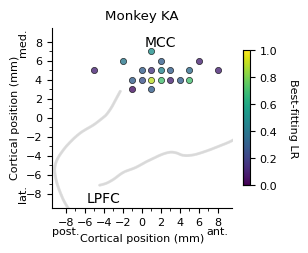

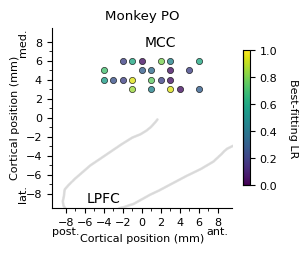

In [5]:
monkeys = res_grid['monkey'].unique()

for monkey in monkeys:
    res_temp = res_grid[res_grid['monkey'] == monkey].copy()

    # remove **_ from session name (keep whats left behind the underscore)
    res_temp['session'] = res_temp['session'].str.split('_').str[1].astype(str)
    fig, ax = plot_on_cortical_grid_best_LR(res_temp, 'best_alpha')
    # save as svg, dpi 300
    fig.savefig(os.path.join(FIGS_PATH, f'figS11a_cortical_grid_{monkey}_best_alpha.svg'), dpi=300, bbox_inches='tight')
    plt.show()

In [6]:
# Export source data (Supplementary Figure 11a)
from popy.source_data import export_source_data

# value drawn at each grid position: as in plot_on_cortical_grid_best_LR, the higher value of the sessions recorded at the same position
tables_s11a, n_s11 = {}, []
for monkey_sd in monkeys:
    df_sd = res_grid[res_grid['monkey'] == monkey_sd]
    pos_sd = df_sd.groupby(['x', 'y'], as_index=False).agg(
        value=('best_alpha', 'max'),
        n_sessions=('session', 'size'),
        sessions=('session', lambda s: ', '.join(v.split('_')[1] for v in s)),
        alphas=('best_alpha', lambda a: ', '.join(f'{v:.2f}' for v in a)))
    pos_sd.columns = ['x position (mm)', 'y position (mm)', 'Plotted value (color)', 'N sessions at this position',
                      'Sessions', 'Best-fitting alpha of each session']
    tables_s11a[f'Monkey {monkey_sd.upper()}: best-fitting learning rate per cortical grid position (MCC)'] = pos_sd
    n_total_sd = int(np.sum(res_alphas_original.monkey.values == monkey_sd))
    n_s11.append(f'{monkey_sd.upper()}: {len(df_sd)} / {n_total_sd}')
n_s11 = ', '.join(n_s11)

export_source_data(
    'Supplementary Figure 11a',
    tables_s11a,
    'Best-fitting learning rate of each session: the alpha (0.05 to 0.95) whose foraging value is best predicted from the MCC '
    'population activity (highest cross-validated R2 of the ridge regression decoder, averaged over the task engagement period '
    f'{eval_window[0]}-{eval_window[1]} s; per session and alpha, R2 values below the {cut_percentile:.0%} quantile over time are removed), '
    f'shown at the recording position on the grid of the recording chamber (1 mm steps; x aligns with the anterior-posterior axis, '
    'y with the medial-lateral axis; posterior on the left). Only sessions '
    f'with significant value coding in MCC at any learning rate are included ({n_s11} sessions). Where two sessions were recorded '
    'at the same position, the higher value is shown; the individual values are listed. No error bars.')

Supplementary Figure 11a: source data saved (20 rows, 23 rows)


---
# Supplementary Fig. S11b: best-fitting learning rate vs. x position

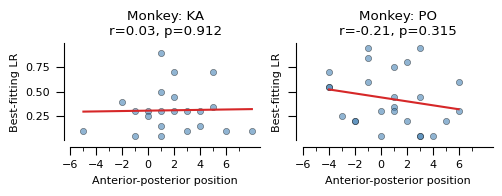

In [7]:
# X coordinate vs best alpha, with linear fit per monkey
from scipy.stats import linregress
# fontsize 8
plt.rcParams.update({'font.size': 8})

fig2, axes2 = plt.subplots(1, 2, figsize=(5, 2), sharey=True, sharex=True)

for i, monkey in enumerate(monkeys):
    monkey_data = res_grid[res_grid['monkey'] == monkey].copy()
    monkey_data['best_alpha_float'] = monkey_data['best_alpha'].astype(float)

    x = monkey_data['x'].to_numpy(dtype=float)
    y = monkey_data['best_alpha_float'].to_numpy()

    axes2[i].scatter(x, y, s=20, alpha=0.6, edgecolors='black', linewidths=0.4, color='steelblue')

    # Linear fit
    slope, intercept, r, pval, _ = linregress(x, y)
    x_line = np.linspace(x.min(), x.max(), 200)
    axes2[i].plot(x_line, slope * x_line + intercept, color='tab:red', linewidth=1.5)
    p_str = "p<0.001" if pval < 0.001 else f"p={pval:.3f}"
    axes2[i].set_title(f'Monkey: {monkey.upper()}\nr={r:.2f}, {p_str}')

    axes2[i].set_xlabel('Anterior-posterior position')
    axes2[i].set_ylabel('Best-fitting LR')
    #axes2[i].grid(True, alpha=0.3)
    import seaborn as sns
    sns.despine(ax=axes2[i])
    axes2[i].spines['left'].set_position(('outward', 5))
    axes2[i].spines['bottom'].set_position(('outward', 5))
    
    # Set x-axis ticks: major ticks at even values (-8, -6, -4, -2, 0, 2, 4, 6, 8)
    # and minor ticks at odd values (-7, -5, -3, -1, 1, 3, 5, 7)
    major_ticks = np.arange(-6, 7, 2)
    minor_ticks = np.arange(-5, 8, 2)
    
    axes2[i].set_xticks(major_ticks)
    axes2[i].set_xticks(minor_ticks, minor=True)
    axes2[i].tick_params(which='major', length=6)
    axes2[i].tick_params(which='minor', length=3, labelbottom=False)

plt.tight_layout()
# save as svg, dpi 300
fig2.savefig(os.path.join(FIGS_PATH, 'figS11b_best_alpha_vs_x_position.svg'), dpi=300, bbox_inches='tight')
plt.show()

In [8]:
# Export source data (Supplementary Figure 11b)
points_s11b = pd.DataFrame({
    'Monkey': res_grid['monkey'].str.upper(),
    'Session': res_grid['session'].str.split('_').str[1],
    'x position (mm)': res_grid['x'],
    'Best-fitting alpha': res_grid['best_alpha'],
})
fits_s11b = []
for monkey_sd in monkeys:
    df_sd = res_grid[res_grid['monkey'] == monkey_sd]
    x_sd = df_sd['x'].to_numpy(dtype=float)
    fit_sd = linregress(x_sd, df_sd['best_alpha'].to_numpy(dtype=float))
    fits_s11b.append({'Monkey': monkey_sd.upper(), 'n sessions': len(df_sd), 'Slope (per mm)': fit_sd.slope,
                      'Intercept': fit_sd.intercept, 'Pearson r': fit_sd.rvalue, 'p value': fit_sd.pvalue,
                      'Fit line from x (mm)': x_sd.min(), 'Fit line to x (mm)': x_sd.max()})

export_source_data(
    'Supplementary Figure 11b',
    {'Best-fitting learning rate of each session vs. x position (dots)': points_s11b,
     'Linear fit per monkey (red line; Pearson correlation, two-sided p value)': pd.DataFrame(fits_s11b)},
    'Best-fitting learning rate (alpha) of each session with significant value coding in MCC (see Supplementary Figure 11a) '
    f'as a function of the x position of the recording on the cortical grid (anterior-posterior axis, mm); {n_s11} sessions. '
    'Red line: least-squares linear fit (scipy.stats.linregress). No error bars.')

Supplementary Figure 11b: source data saved (47 rows, 2 rows)
